<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import random

In [3]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [4]:
len(l)

10000

In [5]:
l[:5]

[7, 10, 2, 7, 6]

In [6]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0265
3     0.0563
4     0.0805
5     0.1074
6     0.1387
7     0.1696
8     0.1368
9     0.1112
10    0.0888
11    0.0577
12    0.0265
Name: count, dtype: float64


<Axes: >

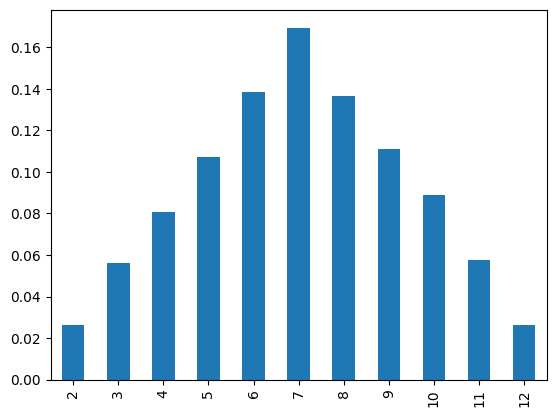

In [7]:
s.plot(kind='bar')

<Axes: >

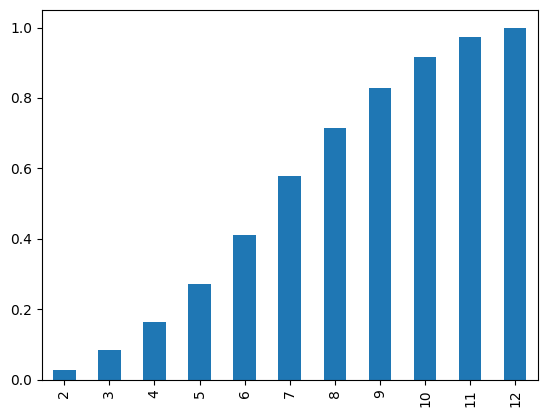

In [8]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [9]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[47.95192003 57.29108901 40.27577608 51.24330575 55.59891649 56.21472116
 47.81890044 48.66307117 53.14201426 50.89478425 46.86477115 45.60005025
 51.77992721 40.74713533 43.84433909 42.83736152 52.10736506 60.05623345
 54.38035398 51.94847663 48.2904766  51.17747319 41.10996101 49.78971832
 48.95431958 59.62651318 51.93596954 45.4278586  57.21618229 52.77263908
 48.77254117 54.53813133 60.79573968 47.54890488 40.79019945 54.27102478
 50.0818983  47.56154147 53.8536842  42.90021569 47.08153421 48.89463659
 45.91213437 55.31672307 45.69176079 49.65636724 41.11219987 47.01046882
 52.1562113  51.64186663 55.07912111 46.19976339 43.0682925  51.45935152
 49.55626804 50.78509876 56.25472411 49.44525757 46.047452   46.56828704
 52.98706433 54.532846   46.00226548 46.48604233 49.00807684 48.54246148
 56.88814751 53.98132556 51.46358247 48.36795824 59.74636789 45.66888782
 52.4452064  54.05977339 60.87999026 48.11103103 41.09194016 43.80652887
 49.91010027 39.89203314 49.30929828 52.93689966 40

In [10]:
sample.mean()

np.float64(49.99407428169805)

(array([  2.,   5.,  49., 110., 225., 274., 215.,  82.,  31.,   7.]),
 array([30.01009885, 33.7161415 , 37.42218414, 41.12822679, 44.83426943,
        48.54031207, 52.24635472, 55.95239736, 59.65844   , 63.36448265,
        67.07052529]),
 <BarContainer object of 10 artists>)

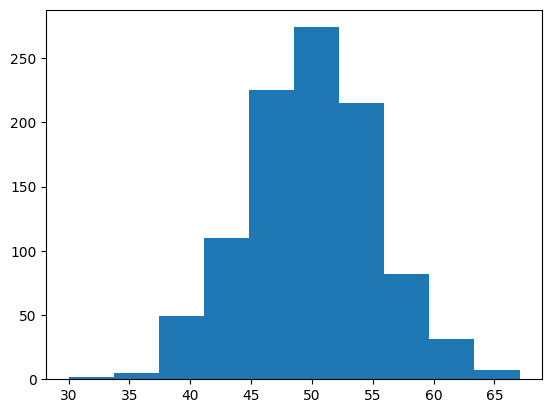

In [11]:
plt.hist(sample,bins=10)

In [12]:
sample_mean=sample.mean()
sample_std=sample.std()

In [13]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [14]:
sample.min()

np.float64(30.010098853653567)

In [15]:
sample.max()

np.float64(67.07052529262768)

In [16]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [17]:
probabilities=[dist.pdf(value) for value in values]

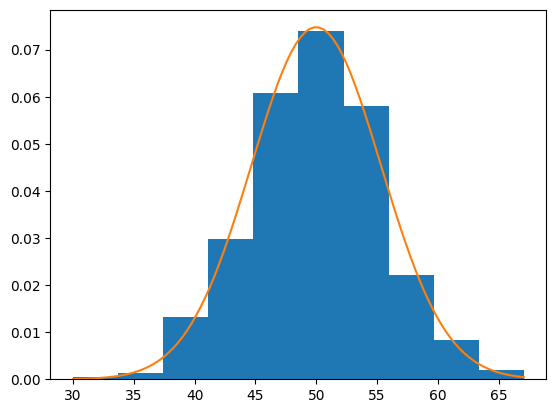

In [18]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_1976/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

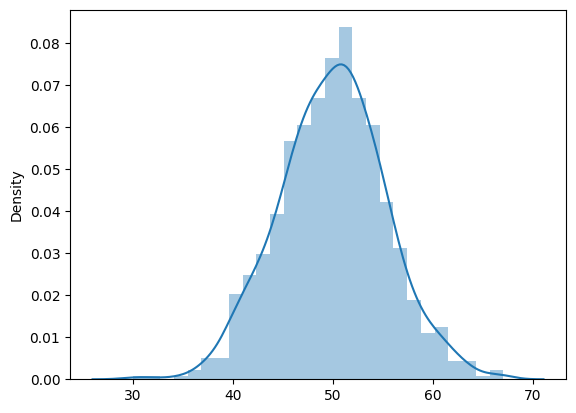

In [19]:
import seaborn as sns
sns.distplot(sample)

KDE

In [20]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [21]:
sample

array([15.00317879, 12.89904276, 25.8006243 ,  6.55677759, 16.62517697,
       23.44520932, 20.26232779, 24.46523143, 21.81998981, 19.40391799,
       20.52993459, 13.60995782, 24.52591852, 25.7348072 , 20.43547184,
       23.64902618, 19.29379687, 10.51046695, 13.81754899, 19.84094344,
       29.80851871, 26.17517071, 21.60709449, 23.04999509, 18.92008752,
       19.46268151, 17.81907736, 17.13612045, 20.16824458, 29.05282151,
       16.95686647, 15.92800853, 21.81077686, 24.78236502, 16.13532234,
       16.73111302, 14.10070659, 21.44923143, 24.99068974, 19.55441038,
        9.92780818, 22.44065101, 14.46611746, 29.22566835, 20.23354087,
       13.66021767, 16.16524031, 17.45796757, 15.01886861, 33.65922591,
       20.97449136, 24.18564027, 11.51843429, 26.90830721, 20.43095597,
       22.56899514, 17.18390654, 18.63376538, 22.75536858, 25.92998739,
       26.79818467, 24.86580408, 19.01676947, 21.00199931, 22.5448892 ,
       19.98794814,  9.01668686, 17.14700185, 24.62820988, 18.91

(array([ 2.,  0.,  2.,  7.,  4.,  6., 11., 11., 14., 11., 18., 11., 32.,
        28., 29., 22., 17., 16., 15., 21., 14.,  7.,  6.,  8., 11., 12.,
        24., 25., 27., 38., 55., 39., 55., 59., 55., 60., 55., 40., 46.,
        26., 17., 12., 13.,  4.,  7.,  2.,  1.,  3.,  1.,  1.]),
 array([ 6.20171621,  7.20320606,  8.20469591,  9.20618576, 10.20767561,
        11.20916546, 12.2106553 , 13.21214515, 14.213635  , 15.21512485,
        16.2166147 , 17.21810455, 18.2195944 , 19.22108425, 20.2225741 ,
        21.22406395, 22.2255538 , 23.22704365, 24.2285335 , 25.23002335,
        26.2315132 , 27.23300305, 28.2344929 , 29.23598275, 30.2374726 ,
        31.23896245, 32.2404523 , 33.24194215, 34.24343199, 35.24492184,
        36.24641169, 37.24790154, 38.24939139, 39.25088124, 40.25237109,
        41.25386094, 42.25535079, 43.25684064, 44.25833049, 45.25982034,
        46.26131019, 47.26280004, 48.26428989, 49.26577974, 50.26726959,
        51.26875944, 52.27024929, 53.27173914, 54.27322899,

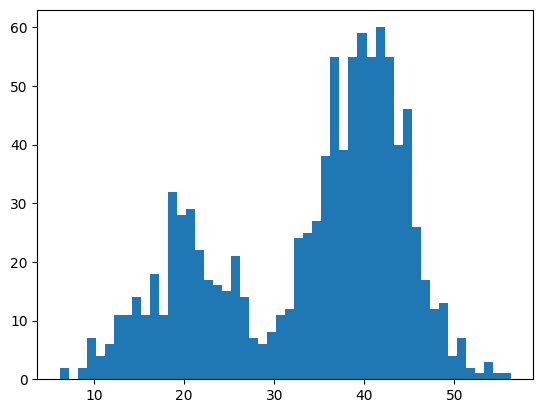

In [22]:
plt.hist(sample,bins=50)

In [24]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
#model.fit(sample)

How to use PDF in data science

In [ ]:
dataset=sns.load_dataset("iris")

In [ ]:
dataset.head()

In [ ]:
an

In [ ]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

In [ ]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

In [ ]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [ ]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [ ]:
tips=sns.load_dataset("tips")

In [ ]:
tips.head()

In [ ]:
sns.kdeplot(data=tips,x="tip",hue="sex")

In [ ]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [25]:
#contour plots